# JPMorgan Chase AI Fraud Detection — Mock Prototype
**MIST 7400 · Mock AI Model Creation (Report Section 5 and Appendix D)**

This notebook builds a scaled-down version of the transaction-fraud classifier a large card issuer such as JPMorgan Chase runs in production. JPMorgan's models monitor hundreds of millions of accounts (PYMNTS, 2023). This prototype uses a public dataset of **284,807 card transactions (492 frauds, 0.17%)** collected by Worldline and the Université Libre de Bruxelles (Dal Pozzolo et al., 2015). At about 150 MB, it is within the "few gigabytes" limit in the project guidelines.

**Contents**
1. Setup and data loading (local file, or automatic download for GitHub and Colab)
2. Class imbalance, and why accuracy is the wrong metric
3. Time-ordered split, walk-forward validation, and how anonymized features relate to production features
4. Three models: anomaly detection, an interpretable baseline, and gradient-boosted trees
5. Test-period evaluation
6. Cost-based binary threshold and its sensitivity
7. **Three-tier action routing**: approve, step-up challenge, or decline
8. SHAP explainability, a segment fairness check, and temporal stability, with a link to SR 26-2 model risk guidance
9. **Inference latency benchmark** against a 100 ms authorization budget
10. Results summary, and a **Model Card / Appendix D summary table**

**Data caveats.** Features V1–V28 are anonymized principal components with no customer demographics, so the fairness check uses transaction-size segments as a proxy. The OpenML copy omits the `Time` column, so rows are kept in their original chronological order and the split is made by row position *(assumption)*.

### How to run
**Locally (Jupyter or VS Code):** install the requirements (`pip install -r requirements.txt`) and run all cells. The notebook reads `data/creditcard.csv` if it exists. Otherwise it downloads the same data from OpenML (dataset 1597) and saves it there.

**Google Colab:** open the notebook and run all cells. The first code cell installs XGBoost and SHAP if they are missing, and the data cell downloads the dataset automatically. Colab needs internet access for this. If the download is blocked, upload `creditcard.csv` from the [Kaggle copy of the ULB dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) into a `data/` folder and re-run.

Every figure is saved at 300 DPI, and every table is saved as a CSV in `outputs/`, for the report and slides.

In [1]:
# Install missing packages (needed on Google Colab; skipped when already installed)
import importlib.util
import subprocess
import sys

for pkg in ["xgboost", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import json
import os
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             recall_score, roc_auc_score)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

with warnings.catch_warnings():          # tqdm prints a harmless notice when SHAP is imported in Jupyter
    warnings.simplefilter("ignore")
    import shap

RNG = 42
os.makedirs("outputs", exist_ok=True)

# Corporate styling used by every figure
NAVY, SLATE, LIGHT, ALERT = "#1F3A5F", "#5B6B7F", "#C9D3DF", "#C0392B"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": NAVY, "axes.labelcolor": SLATE,
    "axes.edgecolor": SLATE, "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})


def save_fig(name):
    # Save the current figure to outputs/ at 300 DPI.
    plt.tight_layout()
    plt.savefig(f"outputs/{name}", dpi=300, bbox_inches="tight")


print(f"Python {platform.python_version()} | xgboost {xgb.__version__} | shap {shap.__version__} "
      f"| pandas {pd.__version__} | numpy {np.__version__}")

Python 3.14.6 | xgboost 3.4.1 | shap 0.54.1 | pandas 3.0.3 | numpy 2.4.6


## 1. Load the data

In [3]:
PATH = "data/creditcard.csv"
if not os.path.exists(PATH):
    from sklearn.datasets import fetch_openml
    print("Local file not found; downloading ULB credit card data from OpenML (dataset 1597)...")
    os.makedirs("data", exist_ok=True)
    fetch_openml(data_id=1597, as_frame=True, parser="auto").frame.to_csv(PATH, index=False)

df = pd.read_csv(PATH)
df["Class"] = df["Class"].astype(str).str.strip("'").astype(int)
print(df.shape)
print(df["Class"].value_counts().rename({0: "legitimate", 1: "fraud"}))
print(f"Fraud rate: {df['Class'].mean():.4%}")
df.head()

(284807, 30)
Class
legitimate    284315
fraud            492
Name: count, dtype: int64
Fraud rate: 0.1727%


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Explore: imbalance and transaction amounts
A model that labels every transaction legitimate would be **99.83% accurate** and catch no fraud. That is why the evaluation below uses precision, recall and the area under the precision–recall curve (PR-AUC) instead of accuracy.

Accuracy of 'never fraud' model: 99.83%
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


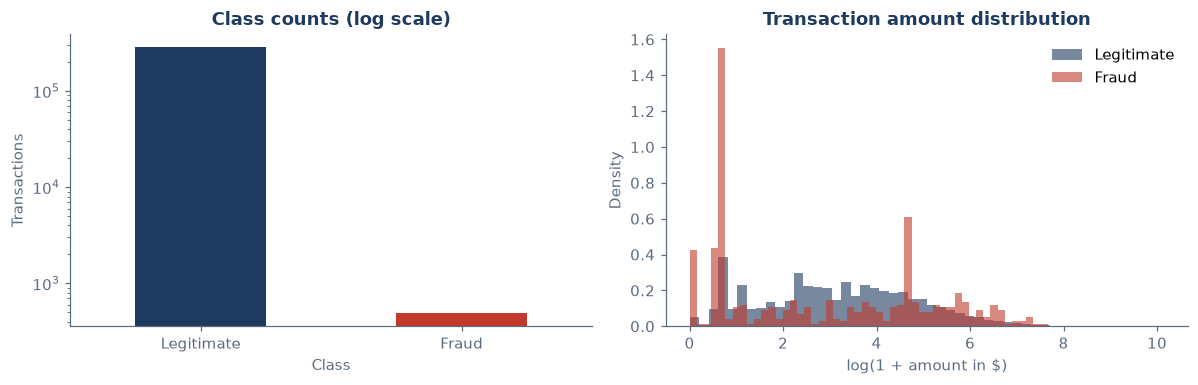

In [4]:
print(f"Accuracy of 'never fraud' model: {1 - df['Class'].mean():.2%}")
print(df.groupby("Class")["Amount"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["Class"].value_counts().plot.bar(ax=ax[0], color=[NAVY, ALERT])
ax[0].set_xticklabels(["Legitimate", "Fraud"], rotation=0)
ax[0].set_yscale("log")
ax[0].set_title("Class counts (log scale)")
ax[0].set_ylabel("Transactions")
for c, col, lab in [(0, NAVY, "Legitimate"), (1, ALERT, "Fraud")]:
    ax[1].hist(np.log1p(df.loc[df.Class == c, "Amount"]), bins=50, alpha=.6, density=True,
               color=col, label=lab)
ax[1].set_title("Transaction amount distribution")
ax[1].set_xlabel("log(1 + amount in $)")
ax[1].set_ylabel("Density")
ax[1].legend()
save_fig("fig_eda.png")
plt.show()

## 3. Feature preparation and a time-ordered split
Production fraud models are trained on the past and scored on the future, and fraud patterns drift (Dal Pozzolo et al., 2018). Shuffling rows would leak future fraud patterns into training and overstate performance, so the split keeps row order. The first **80% is the development period** and the last **20% is the test period**, which is scored once. Inside the development period, **walk-forward cross-validation** (train on earlier folds, score the next one) produces out-of-fold scores, and those are used to tune the decision threshold. A single small validation window would hold too few frauds to tune reliably.

In [5]:
df["log_amount"] = np.log1p(df["Amount"])
FEATURES = [f"V{i}" for i in range(1, 29)] + ["log_amount"]

n = len(df)
cut = int(n * .8)
dev, test = df.iloc[:cut], df.iloc[cut:]
Xtr, ytr = dev[FEATURES], dev["Class"]
Xte, yte = test[FEATURES], test["Class"]
for name, y in [("development", ytr), ("test", yte)]:
    print(f"{name:>12}: {len(y):>7,} rows, {y.sum():>3} frauds ({y.mean():.3%})")
tscv = TimeSeriesSplit(n_splits=5)

 development: 227,845 rows, 417 frauds (0.183%)
        test:  56,962 rows,  75 frauds (0.132%)


### Architecture bridge: from anonymized components to production features
**What V1–V28 are.** To protect cardholder confidentiality, the dataset's authors replaced the original transaction attributes with principal components: V1–V28 are linear blends of the undisclosed original fields. Each component mixes many raw signals, so **no V-feature can be mapped one-to-one to a real-world variable**. V14, for example, cannot honestly be labeled "velocity." What the components do preserve is the information those original fields carried.

**What a production system computes instead.** At authorization time, JPMorgan's streaming pipeline would compute named behavioral aggregates like the ones below (report Section 2.2; Correa Bahnsen et al., 2016). The prototype's PCA inputs stand in for this layer, so the modeling, thresholding and monitoring steps that follow carry over unchanged. Only the feature-engineering step is out of reach here.

| Feature family | Example features (streaming aggregates) | Why it signals fraud |
|---|---|---|
| Velocity | Transactions and spend per card in the last 1 h and 24 h; attempts per merchant in the last 10 min | Card-testing and cash-out bursts |
| Spend deviation | Amount ÷ customer's 90-day median; z-score versus the customer's own baseline | Account takeover changes spending patterns |
| Merchant novelty | First purchase at this merchant or category; merchant fraud rate over 30 days | Fraud migrates to new, high-risk merchants |
| Device and IP telemetry | New device fingerprint; IP–billing country mismatch; emulator or proxy flags | Remote takeover and bot activity |
| Temporal and geographic | Hour-of-day versus habit; distance from last transaction / implied travel speed | "Impossible travel" and off-hours use |
| Network and consortium | Card-network risk score; shared-device links across accounts | Fraud rings that span many accounts |

Engineering these features is the expensive, drift-prone part of the pipeline that Sculley et al. (2015) call "hidden technical debt." In production, a feature store keeps the training and scoring definitions identical.

## 4. Three modeling approaches
| Model | Why it is here | Tradeoff |
|---|---|---|
| Isolation Forest (unsupervised) | Needs no fraud labels and flags unusual transactions, which helps with new fraud patterns (Carcillo et al., 2021) | Usually weaker than supervised models when labels exist |
| Logistic regression (class-weighted) | Transparent and easy to validate under SR 26-2; its coefficients are directly explainable (Rudin, 2019) | Linear, so it misses interactions |
| XGBoost (gradient-boosted trees) | Strong on tabular data (Chen & Guestrin, 2016) and handles non-linear interactions | Less transparent, so it needs SHAP for explanations |

Class imbalance is handled with class weights (`class_weight="balanced"`, `scale_pos_weight`) rather than synthetic oversampling such as SMOTE (Chawla et al., 2002). That keeps the training data realistic and the probabilities easier to calibrate.

In [6]:
scores = {}

t = time.time()
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=RNG,
                      n_jobs=-1).fit(Xtr[ytr == 0])
scores["Isolation Forest"] = -iso.score_samples(Xte)
print(f"Isolation Forest trained in {time.time() - t:.1f}s")

t = time.time()
logit = make_pipeline(StandardScaler(),
                      LogisticRegression(class_weight="balanced", max_iter=2000, C=0.1))
logit.fit(Xtr, ytr)
scores["Logistic regression"] = logit.predict_proba(Xte)[:, 1]
print(f"Logistic regression trained in {time.time() - t:.1f}s")


def make_xgb(pos_weight):
    # XGBoost settings shared by the final model and the walk-forward folds.
    return xgb.XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=pos_weight,
                             eval_metric="aucpr", random_state=RNG, n_jobs=-1)


t = time.time()
spw = (ytr == 0).sum() / (ytr == 1).sum()
xgbm = make_xgb(spw).fit(Xtr, ytr)
scores["XGBoost"] = xgbm.predict_proba(Xte)[:, 1]
print(f"XGBoost trained in {time.time() - t:.1f}s (scale_pos_weight = {spw:.0f})")

# Walk-forward out-of-fold scores on the development period, used for threshold tuning
oof_idx, oof_s = [], []
for a, b in tscv.split(Xtr):
    ya = ytr.iloc[a]
    m = make_xgb((ya == 0).sum() / (ya == 1).sum()).fit(Xtr.iloc[a], ya)
    oof_idx.append(b)
    oof_s.append(m.predict_proba(Xtr.iloc[b])[:, 1])
oof_idx, oof_s = np.concatenate(oof_idx), np.concatenate(oof_s)
y_oof, amt_oof = ytr.values[oof_idx], dev["Amount"].values[oof_idx]
print(f"Walk-forward OOF scores: {len(oof_idx):,} rows, {y_oof.sum()} frauds, "
      f"PR-AUC {average_precision_score(y_oof, oof_s):.3f}")

Isolation Forest trained in 0.7s
Logistic regression trained in 0.4s
XGBoost trained in 1.4s (scale_pos_weight = 545)
Walk-forward OOF scores: 189,870 rows, 314 frauds, PR-AUC 0.800


## 5. Evaluation on the held-out test period
- **PR-AUC (average precision):** the main metric for rare events. A random model scores about the fraud rate (~0.002).
- **ROC-AUC:** reported for comparison, though it looks flattering when legitimate transactions vastly outnumber fraud.
- **Recall at 80% precision:** the share of fraud caught while at least 4 in 5 alerts are real fraud.

In [7]:
def recall_at_precision(y, s, p_min=0.80):
    # Highest recall achievable while precision stays at or above p_min.
    p, r, _ = precision_recall_curve(y, s)
    ok = r[p >= p_min]
    return ok.max() if len(ok) else 0.0


metrics = pd.DataFrame([
    {"Model": name, "PR-AUC (test)": average_precision_score(yte, s),
     "ROC-AUC (test)": roc_auc_score(yte, s), "Recall @ 80% precision": recall_at_precision(yte, s)}
    for name, s in scores.items()]).set_index("Model").round(3)
metrics.to_csv("outputs/table1_model_comparison.csv")
metrics

,PR-AUC (test),ROC-AUC (test),Recall @ 80% precision
Model,,,
Isolation Forest,0.039,0.949,0.00
Logistic regression,0.752,0.986,0.72
XGBoost,0.793,0.987,0.76


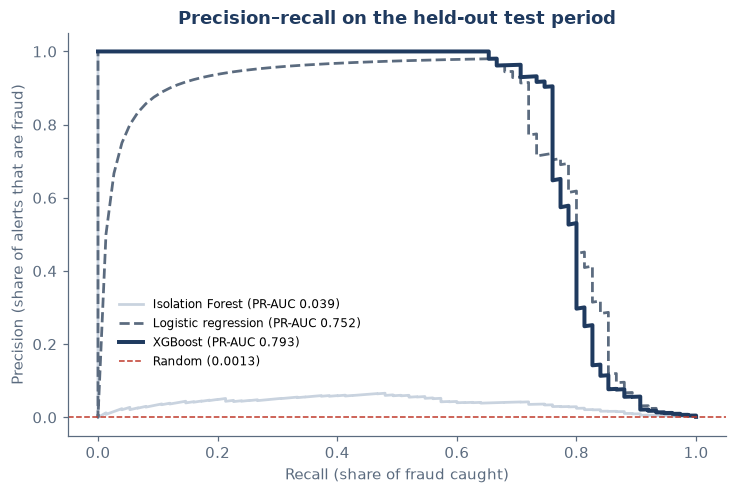

In [8]:
fig, ax = plt.subplots(figsize=(6.8, 4.6))
styles = {"Isolation Forest": (LIGHT, "-", 1.8), "Logistic regression": (SLATE, "--", 1.8),
          "XGBoost": (NAVY, "-", 2.6)}
for name, s in scores.items():
    col, ls, lw = styles[name]
    p, r, _ = precision_recall_curve(yte, s)
    ax.plot(r, p, color=col, ls=ls, lw=lw, label=f"{name} (PR-AUC {average_precision_score(yte, s):.3f})")
ax.axhline(yte.mean(), ls="--", color=ALERT, lw=1, label=f"Random ({yte.mean():.4f})")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Precision–recall on the held-out test period")
ax.legend(loc="lower left", bbox_to_anchor=(0.06, 0.14), fontsize=8)
save_fig("fig_pr_curve.png")
plt.show()

## 6. Choosing the binary decision threshold by cost
The model outputs a probability, and the business chooses where to act on it. The two kinds of error have different costs:
- **Missed fraud (false negative):** the bank loses roughly the transaction amount.
- **False alarm (false positive):** analyst review plus customer friction from a declined or held card. This is set at **$15 per false alarm** *(assumption: about 5 minutes of analyst time plus a share of lost interchange and goodwill; varied in the sensitivity table below)*.

The threshold is tuned on the **walk-forward out-of-fold scores** from the development period, then applied unchanged to the **test** period.

In [9]:
FP_COST = 15.0
GRID = np.linspace(0.01, 0.99, 99)


def cost_at(threshold, y, s, amt, fp_cost=FP_COST):
    # Total cost of a threshold: missed fraud dollars plus false alarms times their unit cost.
    pred = s >= threshold
    missed = amt[(y == 1) & ~pred].sum()
    fps = ((y == 0) & pred).sum()
    return missed + fps * fp_cost, missed, fps


ste = scores["XGBoost"]
amt_te = test["Amount"].values
dev_costs = np.array([cost_at(t, y_oof, oof_s, amt_oof)[0] for t in GRID])
best_t = round(float(GRID[int(np.argmin(dev_costs))]), 2)
print(f"Cost-minimizing threshold on development (out-of-fold): {best_t:.2f}")


def summarize(y, s, amt, t, label):
    # One row of the decision table for a given threshold.
    pred = (s >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    total, missed, _ = cost_at(t, y, s, amt)
    return {"Scenario": label, "Threshold": round(t, 2), "Fraud caught (TP)": tp,
            "Fraud missed (FN)": fn, "False alarms (FP)": fp, "Correct approvals (TN)": tn,
            "Precision": round(tp / max(tp + fp, 1), 3), "Recall": round(tp / (tp + fn), 3),
            "Fraud $ caught": round(amt[(y == 1) & (pred == 1)].sum(), 0),
            "Fraud $ missed": round(missed, 0), "Total cost $": round(total, 0)}


baseline_loss = round(amt_te[yte.values == 1].sum(), 0)
no_model = {"Scenario": "No model (approve all)", "Threshold": np.nan, "Fraud caught (TP)": 0,
            "Fraud missed (FN)": int(yte.sum()), "False alarms (FP)": 0,
            "Correct approvals (TN)": int((yte == 0).sum()), "Precision": np.nan, "Recall": 0.0,
            "Fraud $ caught": 0.0, "Fraud $ missed": baseline_loss, "Total cost $": baseline_loss}
decision = pd.DataFrame([no_model,
                         summarize(yte.values, ste, amt_te, 0.50, "XGBoost, default 0.50"),
                         summarize(yte.values, ste, amt_te, best_t, "XGBoost, cost-tuned")]
                        ).set_index("Scenario")
decision.to_csv("outputs/table2_cost_threshold.csv")
decision

Cost-minimizing threshold on development (out-of-fold): 0.54


,Threshold,Fraud caught (TP),Fraud missed (FN),False alarms (FP),Correct approvals (TN),Precision,Recall,Fraud $ caught,Fraud $ missed,Total cost $
Scenario,,,,,,,,,,
No model (approve all),NaN,0,75,0,56887,NaN,0.00,0.0,7729.0,7729.0
"XGBoost, default 0.50",0.50,57,18,19,56868,0.75,0.76,5091.0,2638.0,2923.0
"XGBoost, cost-tuned",0.54,57,18,17,56870,0.77,0.76,5091.0,2638.0,2893.0


In [10]:
# Sensitivity: how the tuned threshold and test cost move with the false-alarm cost
sens = []
for c in [5, 15, 50, 100]:
    vc = [cost_at(t, y_oof, oof_s, amt_oof, c)[0] for t in GRID]
    t_c = round(float(GRID[int(np.argmin(vc))]), 2)
    total, missed, fps = cost_at(t_c, yte.values, ste, amt_te, c)
    sens.append({"False-alarm cost $": c, "Tuned threshold": t_c, "False alarms": int(fps),
                 "Fraud $ missed": round(missed, 0), "Total test cost $": round(total, 0)})
sens = pd.DataFrame(sens).set_index("False-alarm cost $")
sens.to_csv("outputs/table3_threshold_sensitivity.csv")
sens

,Tuned threshold,False alarms,Fraud $ missed,Total test cost $
False-alarm cost $,,,,
5,0.19,75,2398.0,2773.0
15,0.54,17,2638.0,2893.0
50,0.86,9,2638.0,3088.0
100,0.97,6,3635.0,4235.0


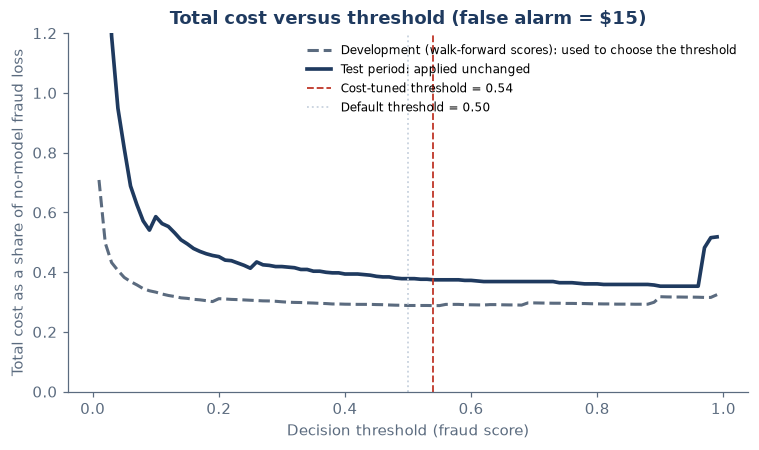

In [11]:
test_costs = np.array([cost_at(t, yte.values, ste, amt_te)[0] for t in GRID])
fig, ax = plt.subplots(figsize=(7, 4.2))
dev_baseline = amt_oof[y_oof == 1].sum()
ax.plot(GRID, dev_costs / dev_baseline, color=SLATE, lw=2, ls="--",
        label="Development (walk-forward scores): used to choose the threshold")
ax.plot(GRID, test_costs / baseline_loss, color=NAVY, lw=2.4,
        label="Test period: applied unchanged")
ax.axvline(best_t, color=ALERT, ls="--", lw=1.2, label=f"Cost-tuned threshold = {best_t:.2f}")
ax.axvline(0.50, color=LIGHT, ls=":", lw=1.2, label="Default threshold = 0.50")
ax.set_xlabel("Decision threshold (fraud score)")
ax.set_ylabel("Total cost as a share of no-model fraud loss")
ax.set_ylim(0, 1.2)
ax.set_title(f"Total cost versus threshold (false alarm = ${FP_COST:.0f})")
ax.legend(fontsize=8)
save_fig("fig_cost_threshold.png")
plt.show()

**Reading the result.** The gap between total cost with no model and with the cost-tuned model is the fraud loss the model avoids in this sample, net of the cost of false alarms. The cost curve is **flat near its minimum**, so thresholds close to 0.50 give almost identical results at a $15 false-alarm cost. The threshold only matters materially once the cost of a false alarm changes, as the sensitivity table shows. When false alarms become more expensive (for example, if customers abandon a card after a wrong decline), the best threshold rises and the bank accepts more missed fraud. This is the recall-versus-friction tradeoff J.P. Morgan Payments describes when it says most fraud alerts are false positives (PYMNTS, 2023).

## 7. Three-tier action routing: approve, step-up challenge, or decline
Banks rarely make a pure yes/no decision. A middle band of scores is usually sent to **step-up authentication** (a one-time code or an app push). That costs a good customer a few seconds instead of a declined card. This cell simulates that policy, with the tier cutoffs taken from the sensitivity table above:

| Tier | Score band | Action | Friction cost to a legitimate customer |
|---|---|---|---|
| 1 | below the $5-tuned threshold | Frictionless auto-approve | $0 |
| 2 | between the two cutoffs | Step-up authentication (automated 2FA) | **$5** *(assumption)* |
| 3 | at or above the $50-tuned threshold | Automated hard decline | **$50** base, **$100** high case *(assumption)* |

**Assumption on step-up:** a step-up challenge stops **90%** of the fraud routed to it. Some account-takeover fraudsters also control the victim's phone or email, so 2FA is not a perfect block. This rate is varied below.

The binary policy uses the cost-tuned threshold from Section 6, with every flagged transaction declined at the flat $15 false-alarm cost used throughout. The two policies price friction differently, so compare them on **fraud intercepted, customers affected and dollars lost**, not only on total cost.

In [12]:
T_LOW = float(sens.loc[5, "Tuned threshold"])      # step-up starts here
T_HIGH = float(sens.loc[50, "Tuned threshold"])    # hard decline starts here
STEPUP_COST, DECLINE_COST, DECLINE_COST_HIGH = 5.0, 50.0, 100.0
STEPUP_STOP_RATE = 0.90                            # ASSUMPTION
print(f"Tier cutoffs from the sensitivity table: step-up at p >= {T_LOW:.2f}, decline at p >= {T_HIGH:.2f}")


def tier_policy(y, s, amt, t_low, t_high, stop_rate=STEPUP_STOP_RATE,
                stepup_cost=STEPUP_COST, decline_cost=DECLINE_COST):
    # Score each tier: volume, friction, fraud intercepted and net dollar loss.
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    tiers = {"Tier 1: auto-approve": s < t_low,
             "Tier 2: step-up challenge": (s >= t_low) & (s < t_high),
             "Tier 3: hard decline": s >= t_high}
    rows = []
    for name, mask in tiers.items():
        legit, fraud = mask & (y == 0), mask & (y == 1)
        fraud_usd = amt[fraud].sum()
        if name.startswith("Tier 1"):
            stopped, lost, friction = 0.0, fraud_usd, 0.0
        elif name.startswith("Tier 2"):
            stopped, lost = fraud.sum() * stop_rate, fraud_usd * (1 - stop_rate)
            friction = legit.sum() * stepup_cost
        else:
            stopped, lost, friction = fraud.sum(), 0.0, legit.sum() * decline_cost
        rows.append({"Tier": name, "Transactions": int(mask.sum()),
                     "% of volume": round(100 * mask.mean(), 3),
                     "Legitimate customers affected": int(legit.sum()) if not name.startswith("Tier 1") else 0,
                     "Frauds in tier": int(fraud.sum()), "Frauds intercepted": round(stopped, 1),
                     "Fraud $ lost": round(lost, 0), "Friction cost $": round(friction, 0),
                     "Net cost $": round(lost + friction, 0)})
    out = pd.DataFrame(rows).set_index("Tier")
    tot = out.sum(numeric_only=True)
    tot["% of volume"] = 100.0
    out.loc["Three-tier total"] = tot
    return out


tiers = tier_policy(yte, ste, amt_te, T_LOW, T_HIGH)

b = decision.loc["XGBoost, cost-tuned"]
binary = pd.Series({"Transactions": len(yte), "% of volume": 100.0,
                    "Legitimate customers affected": int(b["False alarms (FP)"]),
                    "Frauds in tier": int(yte.sum()), "Frauds intercepted": float(b["Fraud caught (TP)"]),
                    "Fraud $ lost": b["Fraud $ missed"],
                    "Friction cost $": b["False alarms (FP)"] * FP_COST, "Net cost $": b["Total cost $"]},
                   name=f"Binary policy (decline at p >= {best_t:.2f})")
nomodel = pd.Series({"Transactions": len(yte), "% of volume": 100.0, "Legitimate customers affected": 0,
                     "Frauds in tier": int(yte.sum()), "Frauds intercepted": 0.0,
                     "Fraud $ lost": baseline_loss, "Friction cost $": 0.0, "Net cost $": baseline_loss},
                    name="No model (approve all)")
routing = pd.concat([tiers, binary.to_frame().T, nomodel.to_frame().T])
int_cols = ["Transactions", "Legitimate customers affected", "Frauds in tier",
            "Fraud $ lost", "Friction cost $", "Net cost $"]
routing[int_cols] = routing[int_cols].astype(float).round(0).astype(int)
routing.to_csv("outputs/table6_three_tier_routing.csv")
routing

Tier cutoffs from the sensitivity table: step-up at p >= 0.19, decline at p >= 0.86


,Transactions,% of volume,Legitimate customers affected,Frauds in tier,Frauds intercepted,Fraud $ lost,Friction cost $,Net cost $
Tier 1: auto-approve,56827,99.763,0,15,0.0,2398,0,2398
Tier 2: step-up challenge,69,0.121,66,3,2.7,24,330,354
Tier 3: hard decline,66,0.116,9,57,57.0,0,450,450
Three-tier total,56962,100.000,75,75,59.7,2422,780,3202
Binary policy (decline at p >= 0.54),56962,100.000,17,75,57.0,2638,255,2893
No model (approve all),56962,100.000,0,75,0.0,7729,0,7729


In [13]:
# Sensitivity of the three-tier result to its two key assumptions
rows = []
for stop in [0.70, 0.90, 1.00]:
    for dc in [DECLINE_COST, DECLINE_COST_HIGH]:
        r = tier_policy(yte, ste, amt_te, T_LOW, T_HIGH, stop_rate=stop, decline_cost=dc).loc["Three-tier total"]
        rows.append({"Step-up stop rate": f"{stop:.0%}", "Decline friction $": dc,
                     "Frauds intercepted": r["Frauds intercepted"], "Fraud $ lost": r["Fraud $ lost"],
                     "Friction cost $": r["Friction cost $"], "Net cost $": r["Net cost $"],
                     "Loss reduction vs no model": f"{1 - r['Net cost $'] / baseline_loss:.1%}"})
tier_sens = pd.DataFrame(rows)
tier_sens.to_csv("outputs/table7_three_tier_sensitivity.csv", index=False)
tier_sens

,Step-up stop rate,Decline friction $,Frauds intercepted,Fraud $ lost,Friction cost $,Net cost $,Loss reduction vs no model
0,70%,50.0,59.1,2470.0,780.0,3250.0,58.0%
1,70%,100.0,59.1,2470.0,1230.0,3700.0,52.1%
2,90%,50.0,59.7,2422.0,780.0,3202.0,58.6%
3,90%,100.0,59.7,2422.0,1230.0,3652.0,52.7%
4,100%,50.0,60.0,2398.0,780.0,3178.0,58.9%
5,100%,100.0,60.0,2398.0,1230.0,3628.0,53.1%


**Reading the result.** The step-up tier lets the bank act on many more suspicious transactions than a hard-decline policy could tolerate. Most legitimate customers caught in it pass a quick check instead of losing the sale, and hard declines are reserved for the highest scores, where false alarms are rare. Whether the three-tier policy beats the binary one on dollars depends on the step-up stop rate and on what a wrong decline really costs. Both are assumptions here, and a bank would measure them from its own authentication and attrition data.

## 8. Explainability: SHAP reason codes
Regulators and customers need to know *why* a transaction was flagged (SR 26-2; GDPR Article 22). SHAP assigns each feature a contribution to each score (Lundberg & Lee, 2017). Below are the global feature importances, then the top reasons for the single highest-scored test transaction.

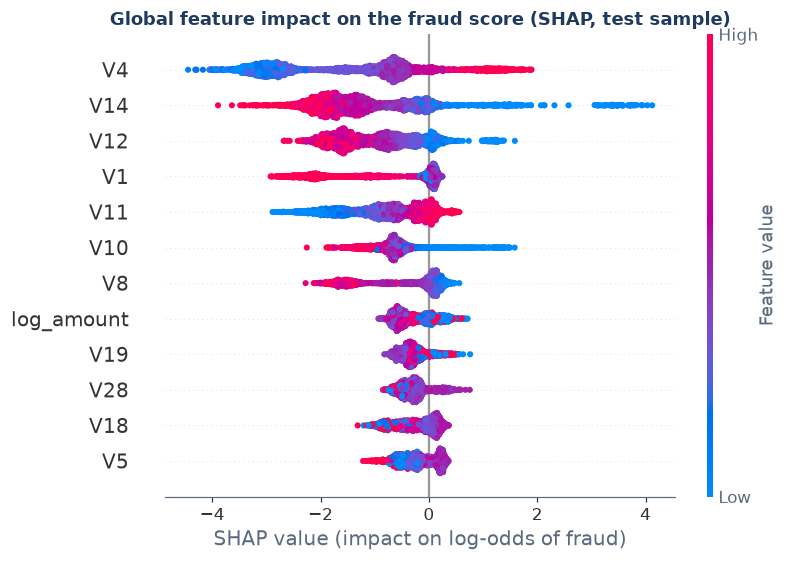

Top 5 features by mean |SHAP|: V4, V14, V12, V1, V11


In [14]:
explainer = shap.TreeExplainer(xgbm)
sample = Xte.sample(3000, random_state=RNG)
sample = pd.concat([sample, Xte[yte == 1]]).drop_duplicates()
sv = explainer.shap_values(sample)

shap.summary_plot(sv, sample, max_display=12, show=False, rng=np.random.default_rng(RNG))
fig = plt.gcf()
fig.set_size_inches(7.5, 5.2)
ax = plt.gca()
ax.set_title("Global feature impact on the fraud score (SHAP, test sample)", color=NAVY, fontweight="bold")
ax.set_xlabel("SHAP value (impact on log-odds of fraud)")
save_fig("fig_shap_summary.png")
plt.show()

top_global = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
print("Top 5 features by mean |SHAP|:", ", ".join(top_global.index[:5]))

In [15]:
idx = int(np.argmax(ste))
x_one = Xte.iloc[[idx]]
contrib = pd.Series(explainer.shap_values(x_one)[0], index=FEATURES)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
print(f"Transaction #{Xte.index[idx]} | amount ${test['Amount'].iloc[idx]:,.2f} | fraud score {ste[idx]:.3f} "
      f"| actual: {'fraud' if yte.iloc[idx] else 'legitimate'}")
print("Top reason codes (SHAP contribution to log-odds):")
print(top.round(3).to_string())

Transaction #251904 | amount $94.82 | fraud score 1.000 | actual: fraud
Top reason codes (SHAP contribution to log-odds):
V14    3.711
V10    1.367
V12    1.233
V4     0.807
V8    -0.746


## 9. Fairness check across transaction-size segments
The dataset has no demographic fields, so a true protected-class audit is impossible here (a limitation stated in the Governance section). As a proxy, this check asks whether the model's error rates are uneven across **transaction-size quartiles**. In a real deployment, the same table would be produced by customer segment (age band, geography, account tenure) to detect disparate impact (Mehrabi et al., 2022).

In [16]:
seg = test[["Amount", "Class"]].copy()
seg["pred"] = (ste >= best_t).astype(int)
seg["Segment"] = pd.qcut(seg["Amount"], 4, labels=["Q1 smallest", "Q2", "Q3", "Q4 largest"])

rows = []
for name, g in seg.groupby("Segment", observed=True):
    tp = int(((g.pred == 1) & (g.Class == 1)).sum())
    fn = int(((g.pred == 0) & (g.Class == 1)).sum())
    fp = int(((g.pred == 1) & (g.Class == 0)).sum())
    tn = int(((g.pred == 0) & (g.Class == 0)).sum())
    rows.append({"Segment": name, "Transactions": len(g), "Frauds": int(g.Class.sum()),
                 "Recall": round(tp / (tp + fn), 3) if tp + fn else np.nan,
                 "False positive rate (per 10k legit)": round(1e4 * fp / (fp + tn), 2)})
fair = pd.DataFrame(rows).set_index("Segment")
fair.to_csv("outputs/table4_segment_fairness.csv")
fair

,Transactions,Frauds,Recall,False positive rate (per 10k legit)
Segment,,,,
Q1 smallest,14334,37,0.838,7.69
Q2,14180,11,0.545,0.71
Q3,14207,9,0.778,0.00
Q4 largest,14241,18,0.722,3.52


**Caution on small counts.** Each segment holds only a few dozen frauds in the test period, so a recall gap of 10–20 points can come from two or three transactions. A production audit would use months of data and confidence intervals before concluding that a segment is treated unfairly.

## 10. Stability over time (drift monitoring)
A production model degrades as fraudsters adapt. Splitting the test period into four consecutive windows shows whether performance holds.

In [17]:
windows = np.array_split(np.arange(len(Xte)), 4)
drift = []
for k, w in enumerate(windows, 1):
    yw, sw = yte.values[w], ste[w]
    drift.append({"Window": f"T{k}", "Transactions": len(w), "Frauds": int(yw.sum()),
                  "PR-AUC": round(average_precision_score(yw, sw), 3) if yw.sum() else np.nan,
                  "Recall @ tuned threshold": round(recall_score(yw, sw >= best_t), 3) if yw.sum() else np.nan})
drift = pd.DataFrame(drift).set_index("Window")
drift.to_csv("outputs/table5_drift_windows.csv")
drift

,Transactions,Frauds,PR-AUC,Recall @ tuned threshold
Window,,,,
T1,14241,23,0.873,0.783
T2,14241,30,0.787,0.767
T3,14240,11,0.892,0.909
T4,14240,11,0.545,0.545


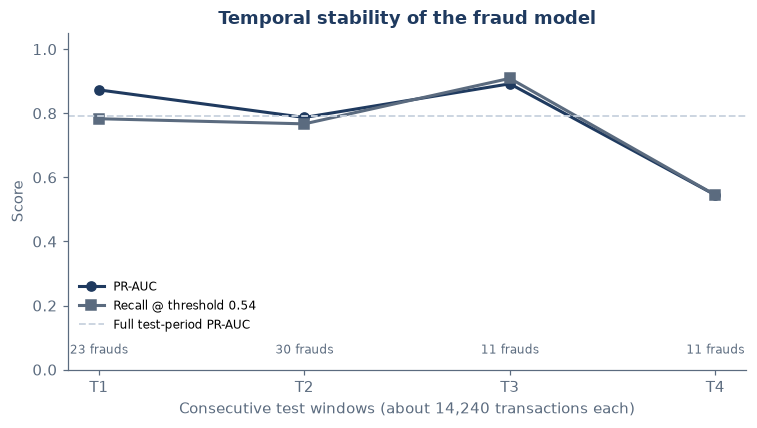

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(drift))
ax.plot(x, drift["PR-AUC"], marker="o", color=NAVY, lw=2, label="PR-AUC")
ax.plot(x, drift["Recall @ tuned threshold"], marker="s", color=SLATE, lw=2,
        label=f"Recall @ threshold {best_t:.2f}")
ax.axhline(metrics.loc["XGBoost", "PR-AUC (test)"], color=LIGHT, ls="--", lw=1.2,
           label="Full test-period PR-AUC")
for i, f in enumerate(drift["Frauds"]):
    ax.annotate(f"{f} frauds", (i, 0.05), ha="center", color=SLATE, fontsize=8)
ax.set_xticks(x, drift.index)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Consecutive test windows (about 14,240 transactions each)")
ax.set_ylabel("Score")
ax.set_title("Temporal stability of the fraud model")
ax.legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 0.08))
save_fig("fig_temporal_drift.png")
plt.show()

### Governance bridge: drift, delayed labels and SR 26-2
**What the dip means.** Performance varies across windows. A weaker window can reflect **concept drift**, meaning fraudsters change tactics so that patterns learned from the past stop matching. It can also be noise: each window rests on only 11–30 frauds, so a single window is weak evidence. A *sustained* fall across several windows is what should trigger action.

**Why monitoring is harder in production.** Fraud labels arrive late. A chargeback can take weeks, and fraud that nobody investigates is recorded as legitimate (Dal Pozzolo et al., 2018). Recall measured today is therefore always recall on last month's traffic. Production monitoring pairs **label-free early signals** (shifts in the score distribution, alert-rate changes, feature population-stability indices) with **label-based checks** once chargebacks settle.

**How this maps to SR 26-2.** The April 2026 interagency model risk guidance from the Federal Reserve, OCC and FDIC, which replaces SR 11-7, expects **ongoing monitoring, outcome analysis and independent validation** in proportion to a model's risk (Board of Governors of the Federal Reserve System et al., 2026). For this model, a defensible design would be:
1. **Monitoring thresholds set in advance.** For example, recall on the latest settled fraud cohort falls below an agreed floor, or the alert rate moves outside a control band.
2. **Drift-triggered retraining instead of a fixed calendar,** using a champion–challenger comparison on out-of-time data.
3. **Independent validation before promotion,** with documented results, the threshold, and a rollback plan.
4. **An audit trail** that records the model version, score and reason codes for every decision (demonstrated in the live demo in `demo/`).

These are the team's recommended controls, not a description of JPMorgan Chase's undisclosed internal practice.

## 11. Inference latency benchmark (100 ms authorization budget)
A card authorization has to be approved or declined while the customer waits. Report Section 2 assumes a fraud-scoring budget of **under 100 ms per transaction** *(assumption; not disclosed by JPMorgan Chase)*. This cell tests the model against that budget the way a scoring service would use it:
- the trained model is **saved and reloaded**, as a fresh scoring service would load it
- **1,000 sequential single-transaction calls** (how authorizations arrive)
- **micro-batches of 10, 100 and 1,000 transactions** (how a service might group requests at peak load)

**What this does not measure:** network hops, feature-store lookups and rules engines around the model. The result shows how much of the budget the model itself uses. Timings depend on the machine, so they are reported with the hardware they ran on.

In [19]:
SLA_MS = 100.0
xgbm.save_model("outputs/fraud_xgb_model.json")
service = xgb.XGBClassifier()
service.load_model("outputs/fraud_xgb_model.json")
assert np.allclose(service.predict_proba(Xte.iloc[:500])[:, 1], ste[:500], atol=1e-6)


def time_calls(batch_size, n_calls):
    # Wall-clock milliseconds for each scoring call of batch_size transactions.
    pool = Xte.sample(n_calls * batch_size, random_state=RNG, replace=n_calls * batch_size > len(Xte))
    batches = [pool.iloc[i * batch_size:(i + 1) * batch_size] for i in range(n_calls)]
    for bt in batches[:20]:                  # warm-up, not timed
        service.predict_proba(bt)
    out = []
    for bt in batches:
        t0 = time.perf_counter()
        service.predict_proba(bt)
        out.append((time.perf_counter() - t0) * 1000)
    return np.array(out)


rows = []
for bs, calls in [(1, 1000), (10, 300), (100, 200), (1000, 100)]:
    ms = time_calls(bs, calls)
    rows.append({"Call type": "Single transaction" if bs == 1 else f"Micro-batch of {bs:,}",
                 "Calls timed": calls, "Mean ms": ms.mean(), "Median (p50) ms": np.median(ms),
                 "p95 ms": np.percentile(ms, 95), "p99 ms": np.percentile(ms, 99),
                 "Per-transaction ms (mean)": ms.mean() / bs,
                 "Meets 100 ms SLA at p99": "Yes" if np.percentile(ms, 99) < SLA_MS else "No"})
latency = pd.DataFrame(rows).set_index("Call type").round(3)
latency.to_csv("outputs/table8_scoring_latency.csv")
print(f"Hardware: {platform.machine()} | {os.cpu_count()} logical CPUs | {platform.system()}")
latency

Hardware: arm64 | 16 logical CPUs | Darwin


,Calls timed,Mean ms,Median (p50) ms,p95 ms,p99 ms,Per-transaction ms (mean),Meets 100 ms SLA at p99
Call type,,,,,,,
Single transaction,1000,0.795,0.766,0.943,1.101,0.795,Yes
Micro-batch of 10,300,1.077,0.841,0.997,1.200,0.108,Yes
Micro-batch of 100,200,0.944,0.903,1.157,1.241,0.009,Yes
"Micro-batch of 1,000",100,1.107,1.073,1.250,1.271,0.001,Yes


In [20]:
# Save model metadata for the live demo (demo/scoring_service.py) and the model card
import datetime

model_meta = {
    "model_version": "jpm-fraud-xgb-" + datetime.date.today().isoformat(),
    "features": FEATURES, "threshold": best_t, "fp_cost_usd": FP_COST,
    "tier_stepup_threshold": T_LOW, "tier_decline_threshold": T_HIGH,
    "stepup_cost_usd": STEPUP_COST, "decline_cost_usd": DECLINE_COST, "stepup_stop_rate": STEPUP_STOP_RATE,
    "train_rows": int(len(Xtr)), "train_frauds": int(ytr.sum()), "test_start_row": int(cut),
    "test_pr_auc": round(float(metrics.loc["XGBoost", "PR-AUC (test)"]), 4),
    "xgboost": xgb.__version__, "shap": shap.__version__,
}
with open("outputs/model_meta.json", "w") as f:
    json.dump(model_meta, f, indent=2)
print(f"Saved outputs/fraud_xgb_model.json and outputs/model_meta.json ({model_meta['model_version']})")

Saved outputs/fraud_xgb_model.json and outputs/model_meta.json (jpm-fraud-xgb-2026-11-23)


## 12. Results summary

In [21]:
best = metrics.loc["XGBoost"]
tuned, base = decision.loc["XGBoost, cost-tuned"], decision.loc["No model (approve all)"]
saved = base["Total cost $"] - tuned["Total cost $"]
three = routing.loc["Three-tier total"]
single = latency.loc["Single transaction"]
print(f"Best model: XGBoost | test PR-AUC {best['PR-AUC (test)']:.3f} | ROC-AUC {best['ROC-AUC (test)']:.3f}")
print(f"Binary policy, threshold {tuned['Threshold']:.2f}: {int(tuned['Fraud caught (TP)'])} of "
      f"{int(yte.sum())} frauds caught (recall {tuned['Recall']:.1%}), precision {tuned['Precision']:.1%}, "
      f"{int(tuned['False alarms (FP)'])} false alarms on {len(yte):,} test transactions")
print(f"Test-period cost: ${base['Total cost $']:,.0f} with no model vs ${tuned['Total cost $']:,.0f} "
      f"with the model -> ${saved:,.0f} avoided ({saved / base['Total cost $']:.1%})")
print(f"Three-tier policy (step-up at {T_LOW:.2f}, decline at {T_HIGH:.2f}): "
      f"{three['Frauds intercepted']:.1f} frauds intercepted, net cost ${three['Net cost $']:,.0f}")
print(f"Latency (single transaction): median {single['Median (p50) ms']:.2f} ms, "
      f"p99 {single['p99 ms']:.2f} ms vs {SLA_MS:.0f} ms budget")

Best model: XGBoost | test PR-AUC 0.793 | ROC-AUC 0.987
Binary policy, threshold 0.54: 57 of 75 frauds caught (recall 76.0%), precision 77.0%, 17 false alarms on 56,962 test transactions
Test-period cost: $7,729 with no model vs $2,893 with the model -> $4,836 avoided (62.6%)
Three-tier policy (step-up at 0.19, decline at 0.86): 59.7 frauds intercepted, net cost $3,202
Latency (single transaction): median 0.77 ms, p99 1.10 ms vs 100 ms budget


## 13. Model Card and Appendix D summary
Every value in this table is generated from the run above, so the card always matches the notebook's outputs.

In [22]:
tq = decision.loc["XGBoost, cost-tuned"]
card = [
    ("Purpose", "Score card transactions for fraud risk in real time; route to approve, step-up or decline"),
    ("Dataset", f"ULB/Worldline European card transactions, Sept. 2013; {len(df):,} rows, "
                f"{int(df.Class.sum())} frauds ({df.Class.mean():.3%}); Dal Pozzolo et al. (2015)"),
    ("Scale", f"{os.path.getsize(PATH) / 1e6:,.0f} MB versus petabyte-scale production data"),
    ("Split", f"Chronological 80/20: {len(Xtr):,} development ({int(ytr.sum())} frauds) / "
              f"{len(Xte):,} test ({int(yte.sum())} frauds); 5-fold walk-forward validation"),
    ("Model", "XGBoost, 400 trees, depth 4, learning rate 0.05, subsample 0.8, "
              f"scale_pos_weight {spw:.0f}, seed {RNG}"),
    ("Benchmarks", f"Logistic regression PR-AUC {metrics.loc['Logistic regression', 'PR-AUC (test)']:.3f}; "
                   f"Isolation Forest PR-AUC {metrics.loc['Isolation Forest', 'PR-AUC (test)']:.3f}"),
    ("Test performance", f"PR-AUC {metrics.loc['XGBoost', 'PR-AUC (test)']:.3f}; "
                         f"ROC-AUC {metrics.loc['XGBoost', 'ROC-AUC (test)']:.3f}"),
    ("Threshold calibration", f"{best_t:.2f}, cost-minimizing on walk-forward scores at ${FP_COST:.0f} "
                              "per false alarm (assumption)"),
    ("Binary decision results", f"TP {int(tq['Fraud caught (TP)'])}, FN {int(tq['Fraud missed (FN)'])}, "
                                f"FP {int(tq['False alarms (FP)'])}, TN {int(tq['Correct approvals (TN)'])}; "
                                f"cost ${tq['Total cost $']:,.0f} vs ${baseline_loss:,.0f} with no model "
                                f"({1 - tq['Total cost $'] / baseline_loss:.1%} reduction)"),
    ("Three-tier routing", f"Step-up at {T_LOW:.2f}, decline at {T_HIGH:.2f}; net cost "
                           f"${routing.loc['Three-tier total', 'Net cost $']:,.0f} "
                           f"(assumes {STEPUP_STOP_RATE:.0%} step-up stop rate)"),
    ("Latency", f"Single transaction median {single['Median (p50) ms']:.2f} ms, p99 {single['p99 ms']:.2f} ms; "
                f"budget {SLA_MS:.0f} ms ({platform.machine()})"),
    ("Explainability", "TreeSHAP reason codes per decision; top global features " + ", ".join(top_global.index[:3])),
    ("Fairness (proxy)", "Recall by amount quartile: " + ", ".join(
        f"{s.split()[0]} {r:.0%}" for s, r in fair["Recall"].items()) + " (small fraud counts)"),
    ("Stability", "PR-AUC by window: " + ", ".join(f"{w} {v:.2f}" for w, v in drift["PR-AUC"].items())),
    ("Known limitations", "Anonymized PCA features (no feature engineering or plain-language reasons); "
                          "no demographics, so fairness is a proxy; two days of 2013 data; "
                          "no Time column (row order used); results vary slightly by hardware"),
    ("Governance", "Recommended: drift-triggered retraining, independent validation and audit trail (SR 26-2)"),
    ("Environment", f"Python {platform.python_version()}, xgboost {xgb.__version__}, shap {shap.__version__}"),
]
model_card = pd.DataFrame(card, columns=["Item", "Detail"]).set_index("Item")
model_card.to_csv("outputs/table9_model_card.csv")
with pd.option_context("display.max_colwidth", None):
    # Jupyter renders text between two "$" signs as math, so show dollar amounts as "USD" on screen
    shown = model_card.assign(Detail=model_card["Detail"].str.replace("$", "USD ", regex=False))
    display(shown.style.set_properties(**{"text-align": "left", "white-space": "normal"}))

,Detail
Item,
Purpose,"Score card transactions for fraud risk in real time; route to approve, step-up or decline"
Dataset,"ULB/Worldline European card transactions, Sept. 2013; 284,807 rows, 492 frauds (0.173%); Dal Pozzolo et al. (2015)"
Scale,148 MB versus petabyte-scale production data
Split,"Chronological 80/20: 227,845 development (417 frauds) / 56,962 test (75 frauds); 5-fold walk-forward validation"
Model,"XGBoost, 400 trees, depth 4, learning rate 0.05, subsample 0.8, scale_pos_weight 545, seed 42"
Benchmarks,Logistic regression PR-AUC 0.752; Isolation Forest PR-AUC 0.039
Test performance,PR-AUC 0.793; ROC-AUC 0.987
Threshold calibration,"0.54, cost-minimizing on walk-forward scores at $15 per false alarm (assumption)"
Binary decision results,"TP 57, FN 18, FP 17, TN 56870; cost $2,893 vs $7,729 with no model (62.6% reduction)"


**AI-use note.** This notebook's code was drafted with help from Claude (Anthropic) and was reviewed and run by the Prototype Lead. Every number above is produced by executing the code.